# Exercise - lab session 6

In the lab, a classification tree was applied to the Carseats data set after
converting Sales into a qualitative response variable. Now you will
seek to predict Sales using regression trees and related approaches,
treating the response as a quantitative variable:


1. Split the data set into a training set and a test set.

2. Fit a regression tree to the training set. Plot the tree, and interpret
the results. What test MSE do you obtain?

3. Use cross-validation in order to determine the optimal level of
tree complexity. Does pruning the tree improve the test MSE?


4. Use the bagging approach in order to analyze this data. What
test MSE do you obtain? Use the `feature_importance_ values` to
determine which variables are most important.

5. Use random forests to analyze this data. What test MSE do
you obtain? Use the `feature_importance_ values` to determine
which variables are most important. Describe the effect of m, the
number of variables considered at each split, on the error rate
obtained.

### Imports

In [1]:
import warnings
warnings.filterwarnings('ignore', message='ModelSpec will move')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.model_selection as skm
from ISLP import load_data
from ISLP.models import ModelSpec as MS

from sklearn.tree import (DecisionTreeRegressor as DTR,
                          plot_tree,
                          export_text)
from sklearn.ensemble import RandomForestRegressor as RF

### Data
As in the lab, we use `ModelSpec` with `intercept=False` (trees do not need an intercept). Qualitative variables
(`ShelveLoc`, `Urban`, `US`) are automatically turned into dummy variables.

In [2]:
Carseats = load_data('Carseats')
model = MS(Carseats.columns.drop('Sales'), intercept=False)
D = model.fit_transform(Carseats)
feature_names = list(D.columns)
X = np.asarray(D)
y = Carseats['Sales']
print(D.shape)
feature_names

(400, 11)


['CompPrice',
 'Income',
 'Advertising',
 'Population',
 'Price',
 'ShelveLoc[Good]',
 'ShelveLoc[Medium]',
 'Age',
 'Education',
 'Urban[Yes]',
 'US[Yes]']

## 1. Training / test split
As in the lab, we keep 30% of the observations for the test set (`random_state=0` for reproducibility).

In [3]:
(X_train,
 X_test,
 y_train,
 y_test) = skm.train_test_split(X,
                                y,
                                test_size=0.3,
                                random_state=0)
X_train.shape, X_test.shape

((280, 11), (120, 11))

## 2. Regression tree
We first fit a small tree (`max_depth=3`, as in the lab) so that it can be plotted and read.

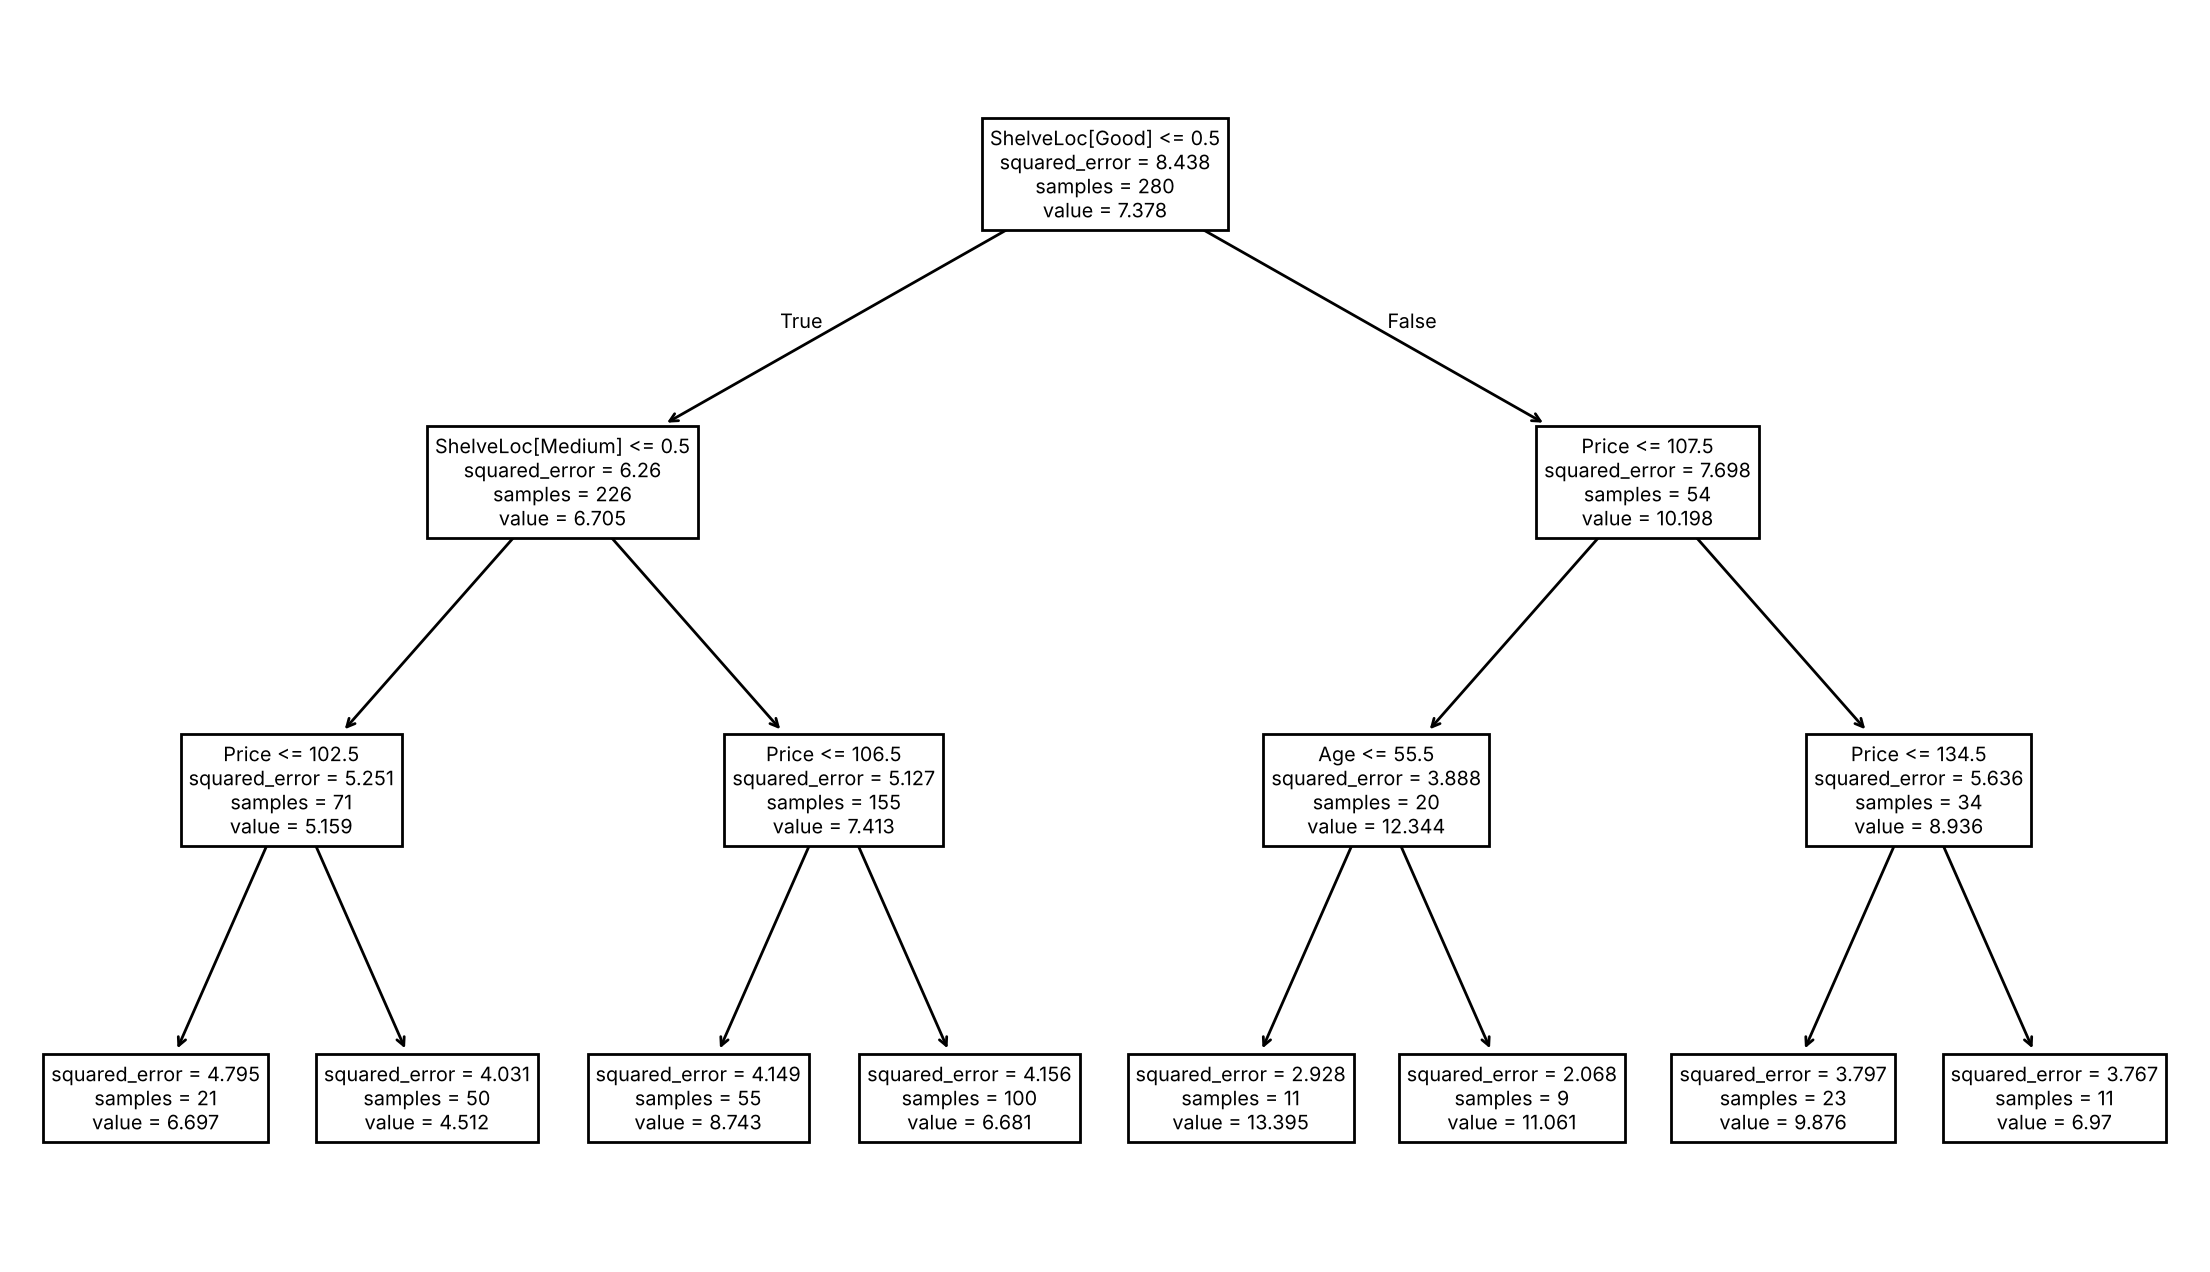

In [4]:
reg = DTR(max_depth=3, random_state=0)
reg.fit(X_train, y_train)
ax = plt.subplots(figsize=(14, 8))[1]
plot_tree(reg,
          feature_names=feature_names,
          ax=ax);

In [5]:
print(export_text(reg,
                  feature_names=feature_names,
                  show_weights=True))

|--- ShelveLoc[Good] <= 0.50
|   |--- ShelveLoc[Medium] <= 0.50
|   |   |--- Price <= 102.50
|   |   |   |--- value: [6.70]
|   |   |--- Price >  102.50
|   |   |   |--- value: [4.51]
|   |--- ShelveLoc[Medium] >  0.50
|   |   |--- Price <= 106.50
|   |   |   |--- value: [8.74]
|   |   |--- Price >  106.50
|   |   |   |--- value: [6.68]
|--- ShelveLoc[Good] >  0.50
|   |--- Price <= 107.50
|   |   |--- Age <= 55.50
|   |   |   |--- value: [13.39]
|   |   |--- Age >  55.50
|   |   |   |--- value: [11.06]
|   |--- Price >  107.50
|   |   |--- Price <= 134.50
|   |   |   |--- value: [9.88]
|   |   |--- Price >  134.50
|   |   |   |--- value: [6.97]



In [6]:
np.mean((y_test - reg.predict(X_test))**2)

np.float64(3.703858275236095)

**Interpretation.** The first split is on `ShelveLoc[Good]`: shelf location is the most important determinant
of sales. Among the other stores, the tree then separates `Medium` from `Bad` shelf locations, and within each
group splits on `Price` (lower price → higher sales). Among stores with a good shelf location, `Price` again matters
most, then `Age` of the local population (younger → higher sales). Each leaf predicts the mean sales of the
training stores falling in it: from about 4.5 (bad location, price > 102.5) to about 13.4 (good location,
price ≤ 107.5, age ≤ 55.5) thousand units.

**Test MSE ≈ 3.70** for this depth-3 tree (RMSE ≈ 1.9 thousand units, to compare with a standard deviation of
`Sales` of about 2.8).

For comparison, a fully grown tree (no depth limit) — this is the tree we will prune in question 3:

In [7]:
reg_full = DTR(random_state=0)
reg_full.fit(X_train, y_train)
print('Number of leaves:', reg_full.get_n_leaves())
np.mean((y_test - reg_full.predict(X_test))**2)

Number of leaves: 277


np.float64(5.083071666666667)

## 3. Pruning by cross-validation
As in the lab, we compute the cost-complexity pruning path of a large tree and choose $\alpha$ (`ccp_alpha`)
by 5-fold cross-validation on the training set.

In [8]:
ccp_path = reg_full.cost_complexity_pruning_path(X_train, y_train)
kfold = skm.KFold(5,
                  shuffle=True,
                  random_state=10)
grid = skm.GridSearchCV(DTR(random_state=0),
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold,
                        scoring='neg_mean_squared_error')
G = grid.fit(X_train, y_train)
print('Best alpha:', G.best_params_['ccp_alpha'])
print('CV MSE   :', -G.best_score_)

Best alpha: 0.020584083333333593
CV MSE   : 4.580748805756194


In [9]:
best_ = grid.best_estimator_
print('Number of leaves of pruned tree:', best_.get_n_leaves())
np.mean((y_test - best_.predict(X_test))**2)

Number of leaves of pruned tree: 55


np.float64(4.431070971603666)

CV error as a function of tree size (number of leaves):

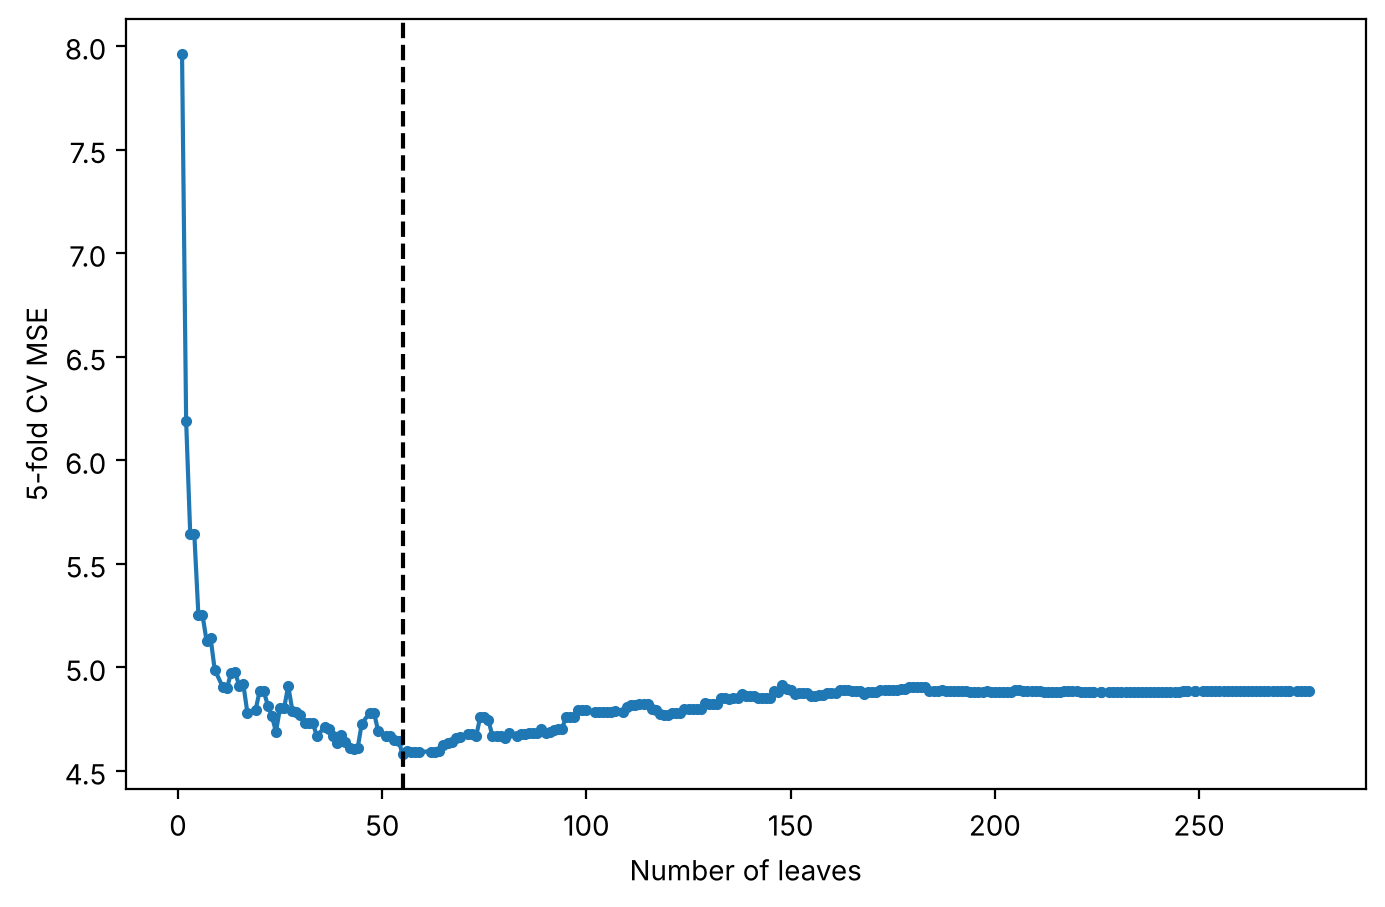

In [10]:
cv_mse = -G.cv_results_['mean_test_score']
n_leaves = [DTR(random_state=0, ccp_alpha=a).fit(X_train, y_train).get_n_leaves()
            for a in ccp_path.ccp_alphas]
ax = plt.subplots(figsize=(8, 5))[1]
ax.plot(n_leaves, cv_mse, marker='o', ms=3)
ax.axvline(best_.get_n_leaves(), ls='--', c='k')
ax.set_xlabel('Number of leaves')
ax.set_ylabel('5-fold CV MSE');

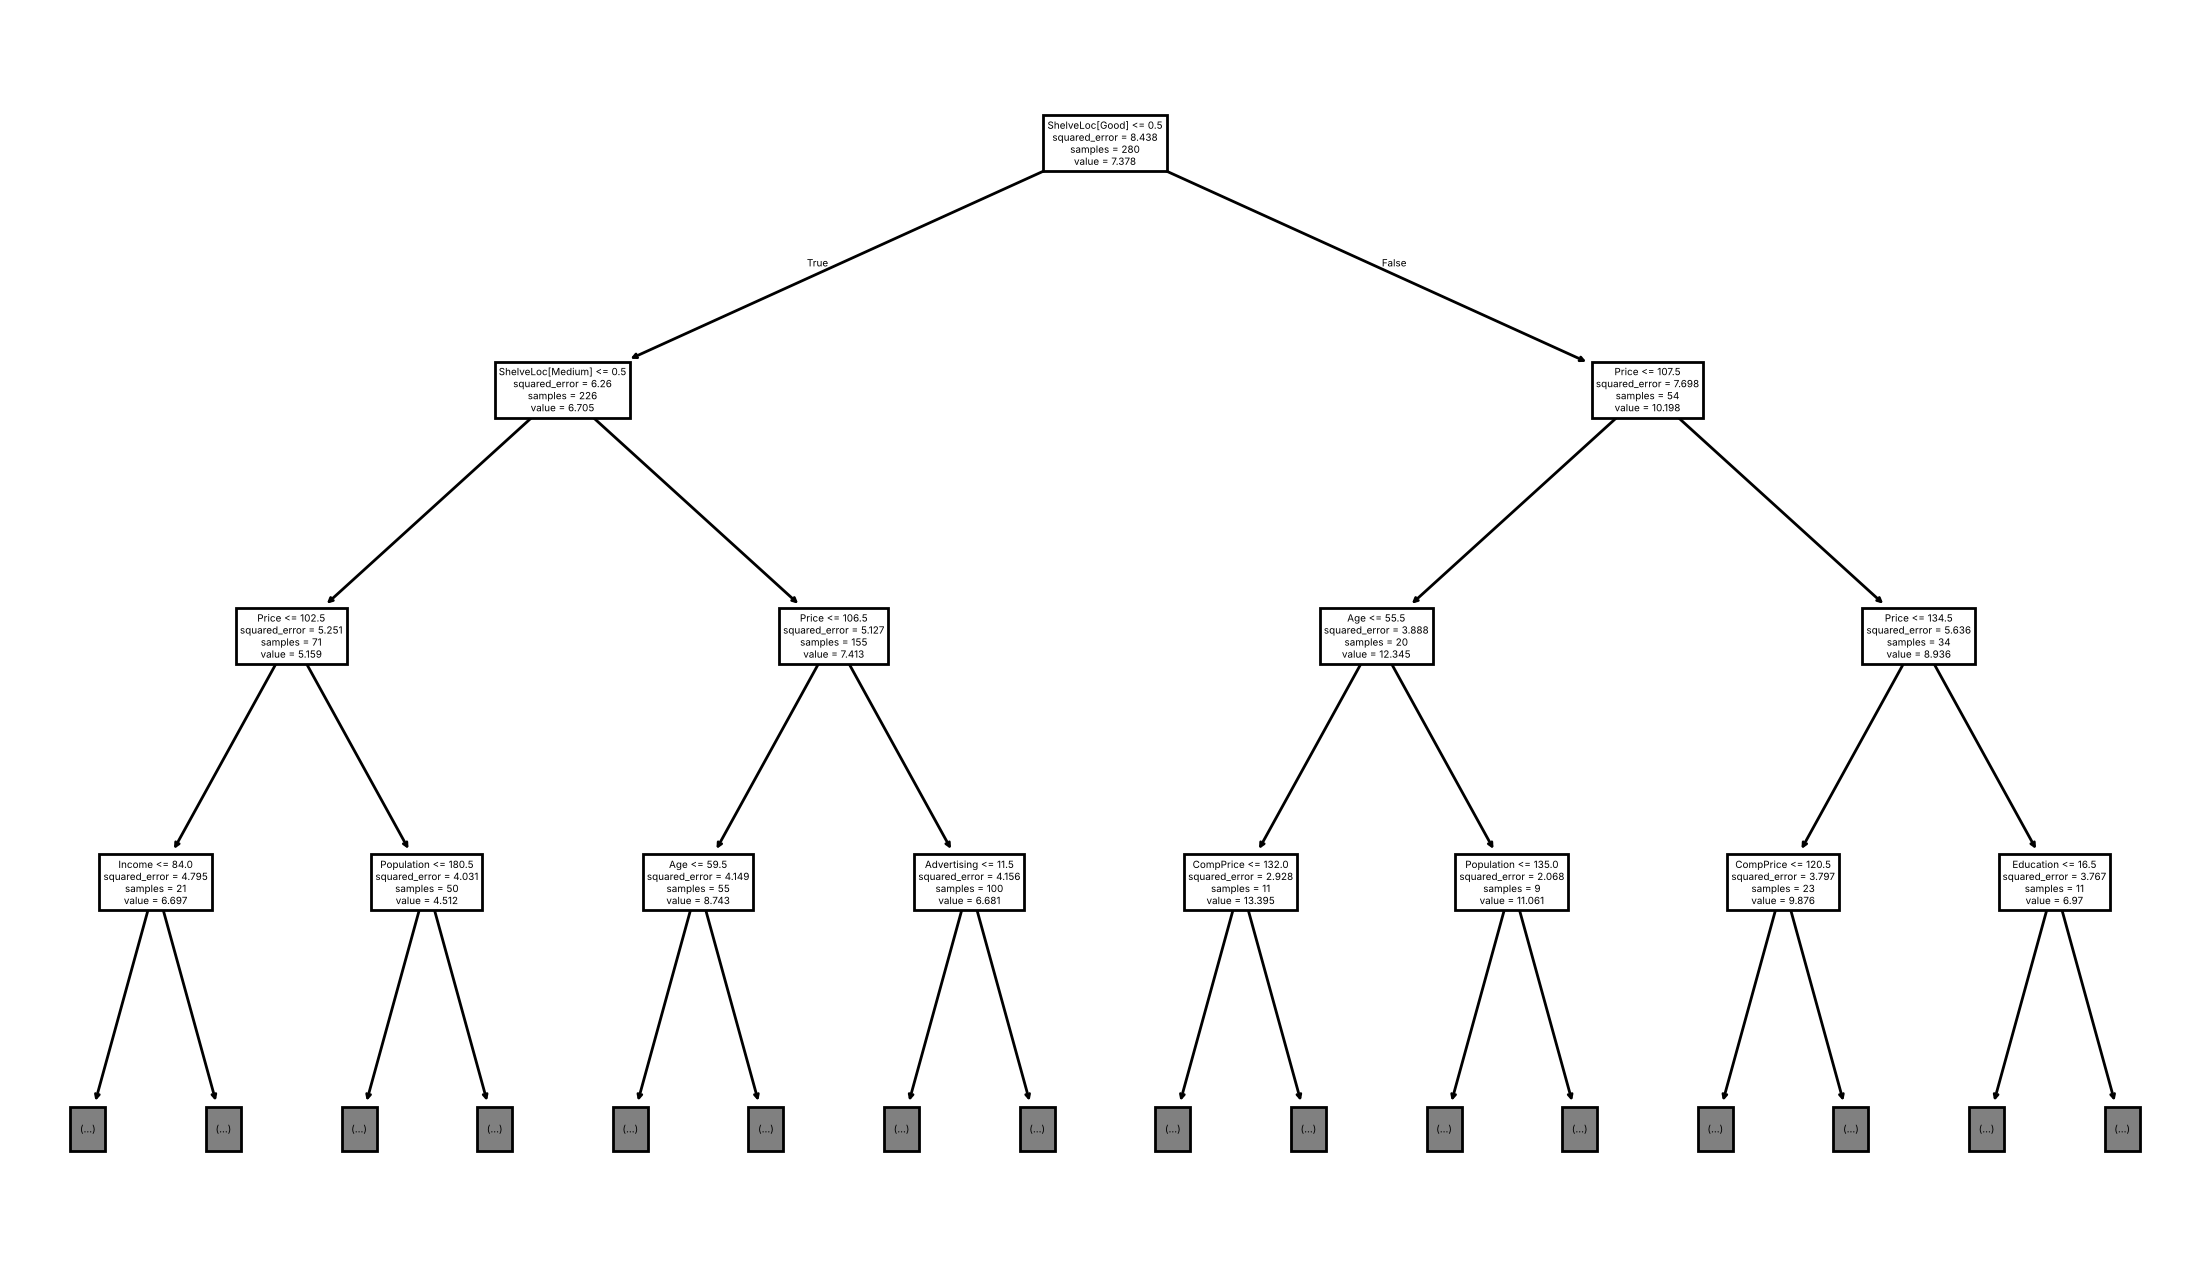

In [11]:
ax = plt.subplots(figsize=(14, 8))[1]
plot_tree(best_,
          feature_names=feature_names,
          max_depth=3,
          ax=ax);

**Does pruning improve the test MSE?** Yes, relative to the fully grown tree: the unpruned tree (277 leaves)
overfits and has a test MSE of ≈ 5.08; the tree pruned by CV ($\alpha \approx 0.021$, 55 leaves) has a test
MSE of ≈ 4.43. Pruning removes the small, noisy splits and so reduces variance.

Two caveats:
- the CV curve is very flat over a wide range of sizes, so the selected size is not precisely determined
  (a "one-standard-error" rule would pick a much smaller tree);
- on this split, the arbitrary depth-3 tree of question 2 (test MSE ≈ 3.70) actually does better than the
  CV-pruned tree. A test MSE computed on 120 observations is noisy, and single trees are high-variance: the
  ranking can change with the seed. This motivates the ensemble methods below.

## 4. Bagging
Bagging is a random forest with $m = p$: all predictors are candidates at every split
(`max_features=X_train.shape[1]`).

In [12]:
bag_carseats = RF(max_features=X_train.shape[1],
                  n_estimators=500,
                  random_state=0).fit(X_train, y_train)
y_hat_bag = bag_carseats.predict(X_test)
np.mean((y_test - y_hat_bag)**2)

np.float64(2.0231969532300087)

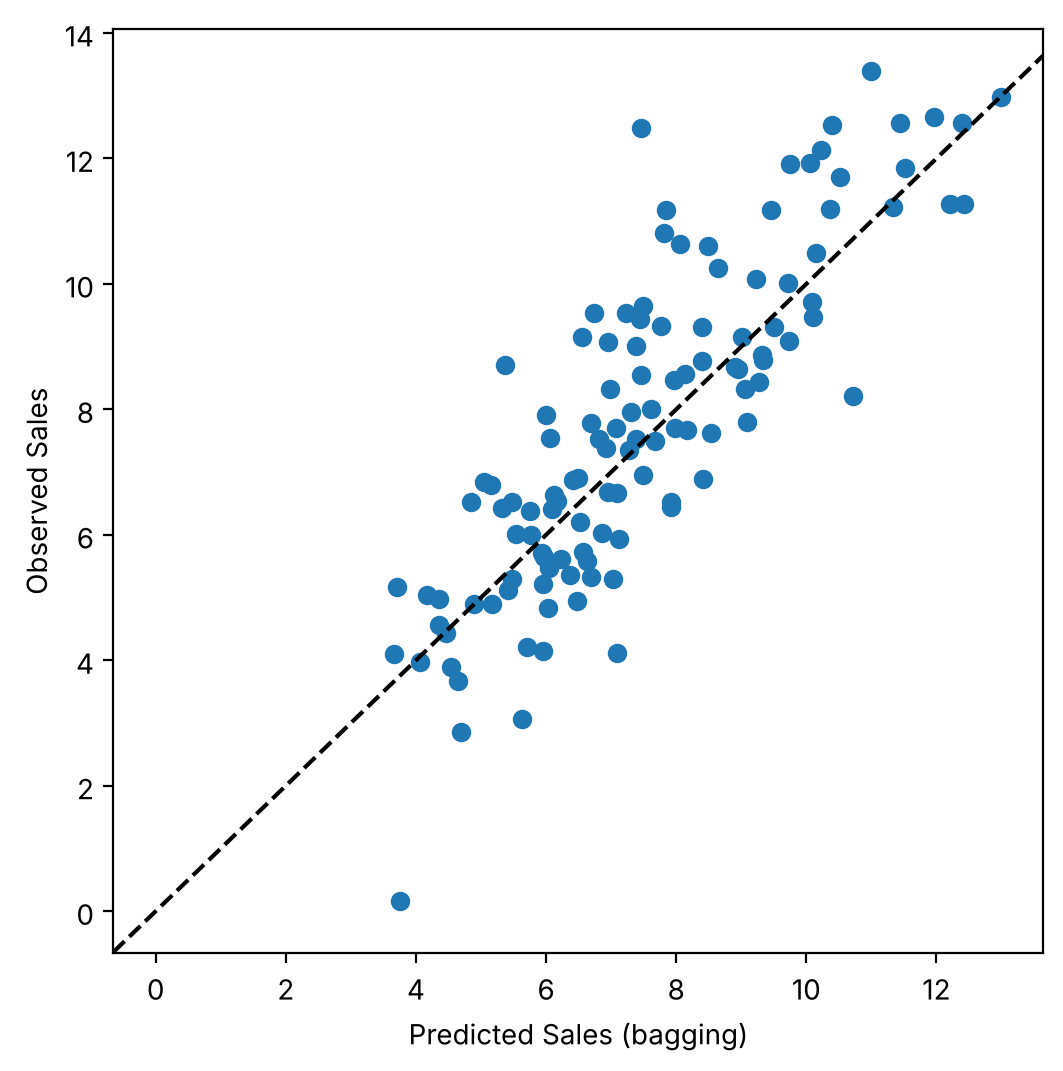

In [13]:
ax = plt.subplots(figsize=(6, 6))[1]
ax.scatter(y_hat_bag, y_test)
ax.axline((0, 0), slope=1, c='k', ls='--')
ax.set_xlabel('Predicted Sales (bagging)')
ax.set_ylabel('Observed Sales');

In [14]:
feature_imp_bag = pd.DataFrame(
    {'importance': bag_carseats.feature_importances_},
    index=feature_names)
feature_imp_bag.sort_values(by='importance', ascending=False)

,importance
Price,0.286431
ShelveLoc[Good],0.220012
Age,0.105442
CompPrice,0.100790
ShelveLoc[Medium],0.085062
Advertising,0.068720
Income,0.053610
Population,0.039233
Education,0.029787
US[Yes],0.006594


**Interpretation.** **Test MSE ≈ 2.02**, roughly half that of the best single tree: averaging 500 trees grown
on bootstrap samples greatly lowers the variance. The importance values (mean decrease in RSS, normalised to sum
to one) show that `Price` (0.29) and `ShelveLoc[Good]` (0.22) are by far the most important variables, followed
by `Age` and `CompPrice` (≈ 0.10 each), `ShelveLoc[Medium]` and `Advertising`. `Education`, `US` and `Urban`
contribute very little.

## 5. Random forests
Default choice for regression in ISLP: $m \approx p/3$. With $p = 11$ predictors (after dummy coding), we use
`max_features=4`.

In [15]:
p = X_train.shape[1]
RF_carseats = RF(max_features=4,
                 n_estimators=500,
                 random_state=0).fit(X_train, y_train)
y_hat_RF = RF_carseats.predict(X_test)
np.mean((y_test - y_hat_RF)**2)

np.float64(2.1340836263600056)

In [16]:
feature_imp_RF = pd.DataFrame(
    {'importance': RF_carseats.feature_importances_},
    index=feature_names)
feature_imp_RF.sort_values(by='importance', ascending=False)

,importance
Price,0.254677
ShelveLoc[Good],0.177810
Age,0.118655
CompPrice,0.097139
Advertising,0.082345
Income,0.079630
Population,0.065874
ShelveLoc[Medium],0.054932
Education,0.045320
US[Yes],0.013459


### Effect of $m$ (`max_features`) on the error
We refit the forest for every value of $m$ from 1 to $p$ ($m = p$ is bagging) and record the test MSE and the
out-of-bag (OOB) MSE.

In [17]:
m_values = range(1, p + 1)
test_mse, oob_mse = [], []
for m in m_values:
    rf = RF(max_features=m,
            n_estimators=500,
            oob_score=True,
            random_state=0).fit(X_train, y_train)
    test_mse.append(np.mean((y_test - rf.predict(X_test))**2))
    oob_mse.append(np.mean((y_train - rf.oob_prediction_)**2))
pd.DataFrame({'m': m_values, 'test MSE': test_mse, 'OOB MSE': oob_mse}).set_index('m')

,test MSE,OOB MSE
m,,
1,3.186779,4.319524
2,2.676942,3.608711
3,2.326166,3.117088
4,2.134084,2.833603
5,2.029584,2.684371
6,2.032226,2.573973
7,2.017354,2.552992
8,1.985798,2.480683
9,2.009830,2.565974


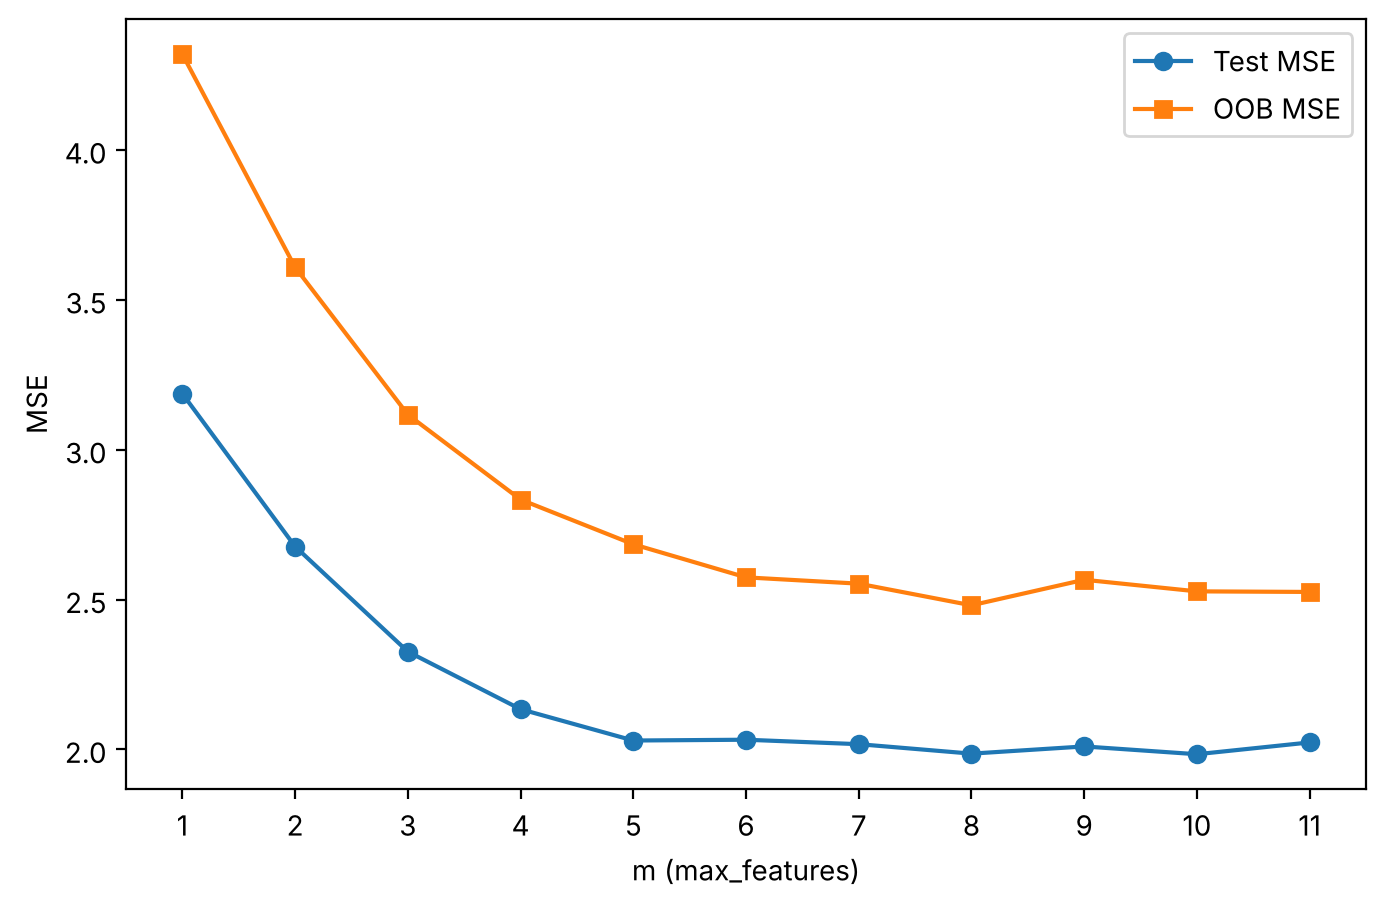

In [18]:
ax = plt.subplots(figsize=(8, 5))[1]
ax.plot(m_values, test_mse, marker='o', label='Test MSE')
ax.plot(m_values, oob_mse, marker='s', label='OOB MSE')
ax.set_xlabel('m (max_features)')
ax.set_ylabel('MSE')
ax.set_xticks(list(m_values))
ax.legend();

**Random forest with $m=4$: test MSE ≈ 2.13**, slightly *worse* than bagging (≈ 2.02) on this split.

**Effect of $m$.** With very small $m$ the error is high (test MSE ≈ 3.19 for $m=1$, 2.68 for $m=2$): at most
splits the tree is not allowed to use the two dominant predictors (`Price`, `ShelveLoc[Good]`), so individual
trees are strongly biased. The error falls quickly as $m$ increases and is essentially flat from $m \approx 5$
to $m = p = 11$ (between 1.98 and 2.03). The OOB error shows the same pattern, without using the test set.

So here decorrelating the trees brings no gain: because a few predictors dominate, the bias cost of a small $m$
outweighs the variance reduction from decorrelation. Random forests help most when many predictors are
correlated or moderately informative; with `Carseats`, bagging (or any $m \geq 5$) does as well as it gets.

The importance ranking is the same as with bagging (`Price`, `ShelveLoc[Good]`, `Age`, `CompPrice`, then
`Advertising`, `Income`), but importance is spread more evenly: with $m<p$, weaker predictors (`Income`,
`Population`) are used more often because the strong ones are not always available.

## Summary of test MSEs

In [19]:
summary = pd.Series({
    'Regression tree (max_depth=3)': np.mean((y_test - reg.predict(X_test))**2),
    'Full regression tree': np.mean((y_test - reg_full.predict(X_test))**2),
    'Pruned tree (CV)': np.mean((y_test - best_.predict(X_test))**2),
    'Bagging (m = p)': np.mean((y_test - y_hat_bag)**2),
    'Random forest (m = 4)': np.mean((y_test - y_hat_RF)**2),
}, name='Test MSE')
summary.round(3)

Regression tree (max_depth=3)    3.704
Full regression tree             5.083
Pruned tree (CV)                 4.431
Bagging (m = p)                  2.023
Random forest (m = 4)            2.134
Name: Test MSE, dtype: float64